# Using SHAP vs residual error plots

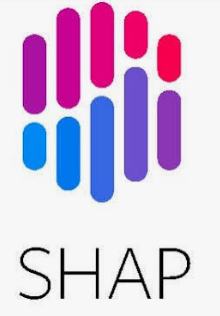

<i>

To show SHAP vs ERROR visual works -- I'll create three synthetic datasets and <u> we're going to progressively add more noise in the `noise` parameter. </u>

Feel free to experiment with the number of features, noise, models etc!



### <i> Imports

In [135]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn import metrics
from sklearn.datasets import make_regression


### <i> Loading datasets

We're going to load three datasets. Each has a bit more noise than the previous. 

In [ ]:
# DATASET 1 -- 1 Feature
X, y = make_regression(
    n_samples=1000,    # How many rows you have
    n_features=2,      # How many X columns you will receive.
    random_state=42    # Seed
)

df_1 = pd.DataFrame(X, columns=["Feature_1", "Feature_2"])
df_1["Target"] = y

df_1.head()


# DATASET 2 -- 2 features
X, y = make_regression(
    n_samples=1000,    # How many rows you have
    n_features=2,      # How many X columns you will receive.
    noise=5,          # Increases the amount of noise in the dataset.
    random_state=42    # Seed
)

df_2 = pd.DataFrame(X, columns=["Feature_1","Feature_2"])
df_2["Target"] = y

# DATASET 3 -- 3 features, added noise.
X, y = make_regression(
    n_samples=1000,    # How many rows you have
    n_features=2,      # How many X columns you will receive.
    noise=15,          # Increases the amount of noise in the dataset.
    random_state=42    # Seed
)

df_3 = pd.DataFrame(X, columns=["Feature_1","Feature_2"])
df_3["Target"] = y

# Place the dataframes into a list to iterate over.
dfs = [df_1, df_2, df_3]


### <i> Splitting, Training, Shapley values

We do the training, splitting, fitting, shapley values all in a for-loop.

Then we append the results in a list of dictionaries. 

In [139]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

results = []

# For each dataframe, X, y split, train test split,
# train/fit XGBoost regressor, and append the features,
#  metrics, shap values all into a dictionary to later.
for i, df in enumerate(dfs, start=1):

    # Separate features and target
    X = df.drop("Target", axis=1)
    y = df["Target"]

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # Train model
    model = XGBRegressor(
        n_estimators=300,
        max_depth=6,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Get the prediction error.
    residuals = y_test - y_pred

    # Generate SHAP values
    explainer = shap.TreeExplainer(model)
    shap_values = explainer(X_test)

    # Evaluate (since we can't name variables by the iterator values)
    results.append({
        "Dataset": f"Dataset {i}",
        "Features": X.shape[1],
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "shap_values": shap_values,
        "residuals": residuals,
        "R2": r2_score(y_test, y_pred),
        "Model": model,
        "X_test": X_test,
        "y_test": y_test,
        "y_pred": y_pred
    })

results_df = pd.DataFrame(results)

results_df[["Dataset", "Features", "MAE", "RMSE", "R2"]].round(4)

,Dataset,Features,MAE,RMSE,R2
0,Dataset 1,2,1.1785,2.6863,0.9953
1,Dataset 2,2,5.1644,6.4826,0.9733
2,Dataset 3,2,14.7735,18.5793,0.7989


### <i> SHAP vs ERROR scatter plots

Finally, we create a SHAP vs ERROR scatter plot for each feature.

Each column represents a different dataset.

Each row represents a different feature.

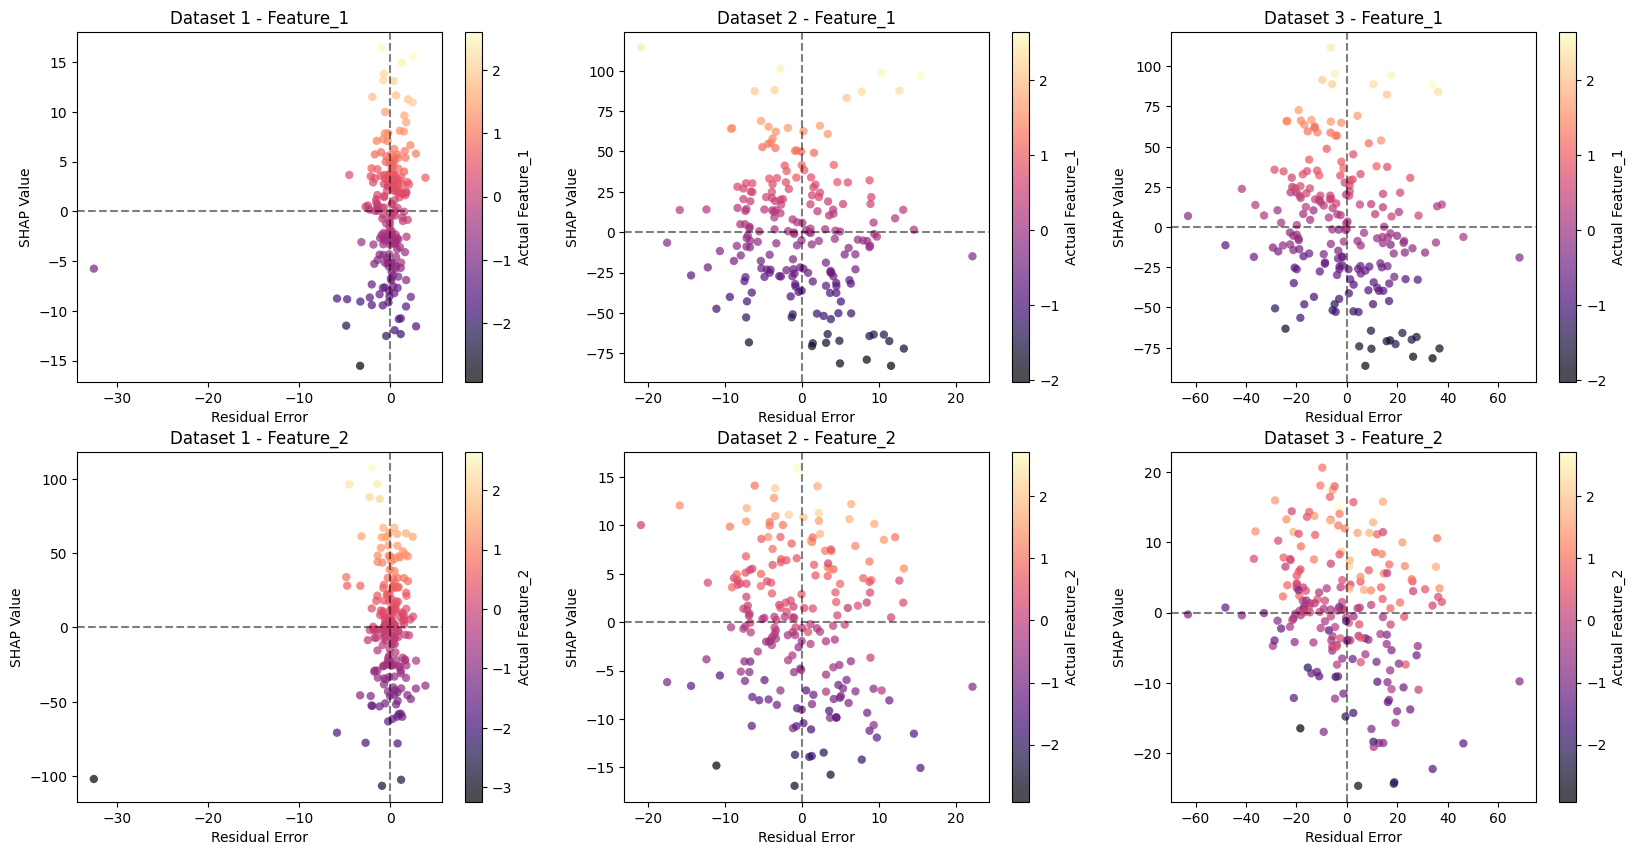

In [146]:
import matplotlib.pyplot as plt
import numpy as np

# First, we create the canvas
fig, axes = plt.subplots(
    nrows=max_features,
    ncols=n_datasets,
    figsize=(20, 10),
    squeeze=False
)

# For each Dataset...
for col_index, result in enumerate(results):

    # Take the values we need for the plot.
    X_test = result["X_test"]
    shap_values = result["shap_values"]
    residuals = result["residuals"]

    # And for each feature.
    for row_index, column in enumerate(X_test.columns):

        # Show where the plot is going on the canvas.
        ax = axes[row_index, col_index]

        # Get feature index.
        feature_index = X_test.columns.get_loc(column)

        # SHAP values
        feat_shap_values = shap_values.values[:, feature_index]

        # Raw feature values
        feat_raw_values = X_test[column].values

        # Scatterplot
        sc = ax.scatter(
            residuals,
            feat_shap_values,
            c=feat_raw_values,
            cmap="magma",
            alpha=0.7,
            edgecolors="none"
        )

        # Reference lines
        ax.axhline(0, color="black", linestyle="--", alpha=0.5)
        ax.axvline(0, color="black", linestyle="--", alpha=0.5)

        # Titles and labels
        ax.set_title(f"Dataset {col_index + 1} - {column}")
        ax.set_xlabel("Residual Error")
        ax.set_ylabel("SHAP Value")

        # Set the colorbar on the right plot, and add a label.
        fig.colorbar(sc, ax=ax, label=f"Actual {column}")

# Done
plt.show()